In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("viral_songs.csv")

df.shape
df.head()
df.info()
df.describe()
df.isnull().sum()
df.duplicated().sum()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_id          10000 non-null  object 
 1   track_name        10000 non-null  object 
 2   artist            10000 non-null  object 
 3   genre             10000 non-null  object 
 4   release_year      10000 non-null  int64  
 5   duration_sec      10000 non-null  int64  
 6   danceability      10000 non-null  float64
 7   energy            10000 non-null  float64
 8   valence           10000 non-null  float64
 9   tempo_bpm         10000 non-null  float64
 10  acousticness      10000 non-null  float64
 11  instrumentalness  10000 non-null  float64
 12  speechiness       10000 non-null  float64
 13  liveness          10000 non-null  float64
 14  loudness_db       10000 non-null  float64
 15  streams           10000 non-null  int64  
 16  viral             10000 non-null  int64  

,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
0,track_00001,Track_00001,Artist_1519,Pop,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,661412,1
1,track_00002,Track_00002,Artist_0458,Electronic,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1114175,1
2,track_00003,Track_00003,Artist_1386,Hip-Hop,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,105832,1
3,track_00004,Track_00004,Artist_0865,Classical,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,915397,0
4,track_00005,Track_00005,Artist_0192,Pop,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,3690733,1


,count
viral,
0,6395
1,3605


,proportion
viral,
0,0.6395
1,0.3605


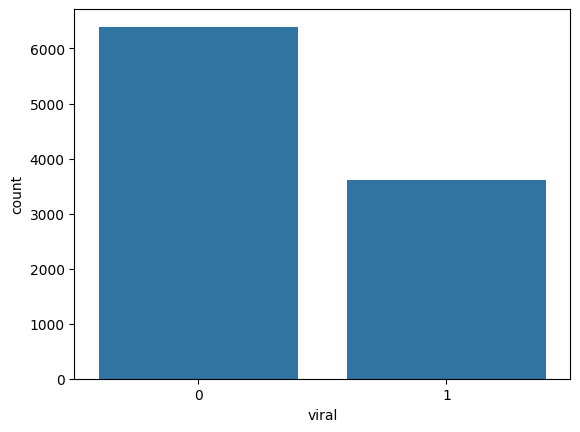

In [13]:
# Eksplorasi target (viral)
display(df["viral"].value_counts())
display(df["viral"].value_counts(normalize=True))

sns.countplot(x="viral", data=df)
plt.show()

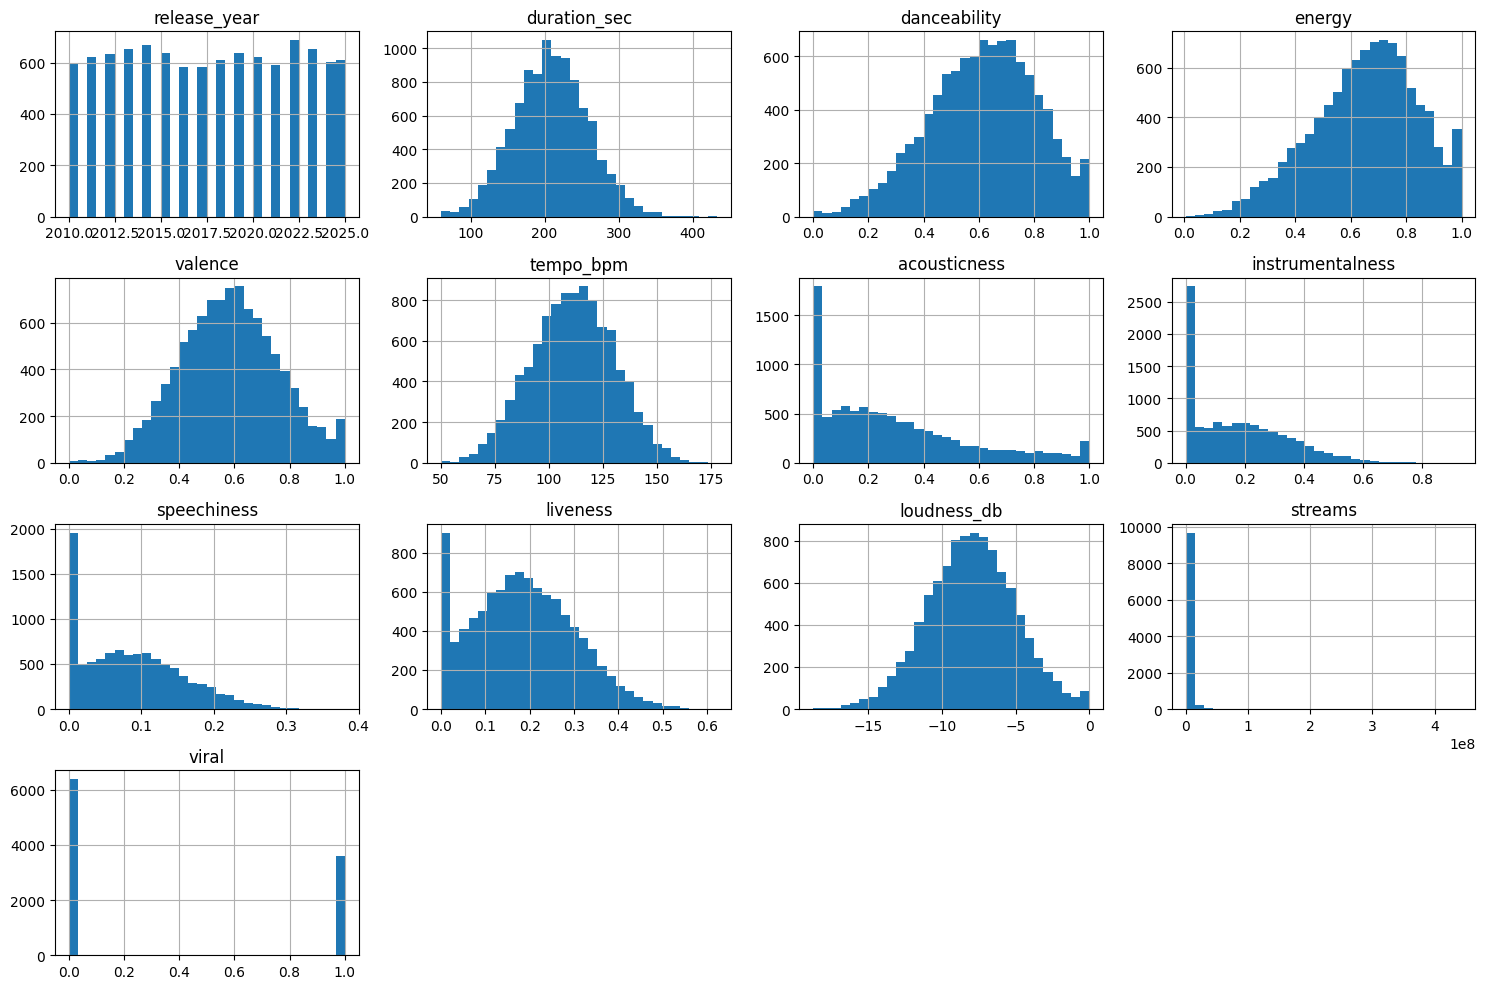

,viral
acousticness,-0.359108
instrumentalness,-0.071792
speechiness,-0.018161
loudness_db,-0.011700
duration_sec,-0.004712
release_year,0.003601
liveness,0.005411
tempo_bpm,0.016373
valence,0.204971
streams,0.266393


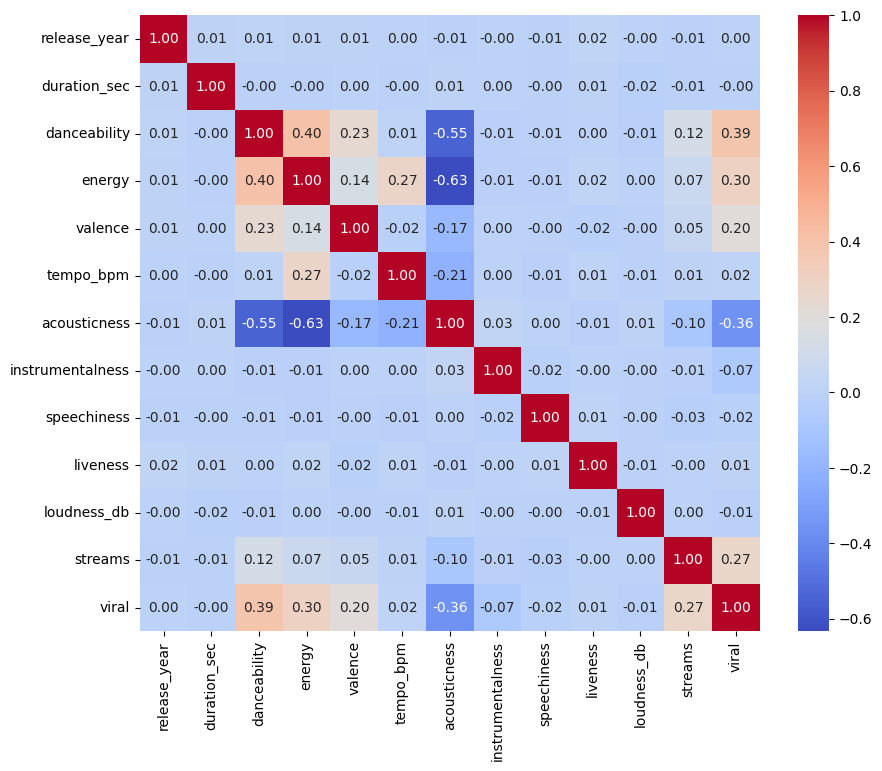

,viral
genre,
Latin,0.646602
Pop,0.617764
Hip-Hop,0.611217
Electronic,0.506559
R&B,0.405263
Rock,0.326568
Country,0.238854
Indie,0.138973
Jazz,0.063212


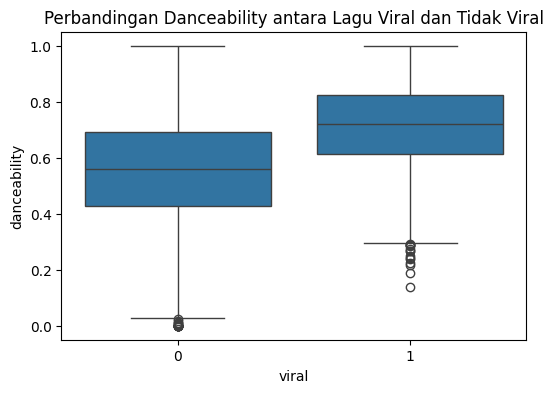

,count,mean,std,min,25%,50%,75%,max
viral,,,,,,,,
0,6395.0,4.714607e+05,1.081595e+06,134.0,47401.0,149193.0,436244.0,19345373.0
1,3605.0,5.864593e+06,1.554017e+07,8937.0,545278.0,1694602.0,5224834.0,443068342.0


In [16]:
# Ekplorasi Fitur

# Memperbaiki typo 'valance' menjadi 'valence'
fitur_num = ["release_year", "duration_sec", "danceability", "energy", "valence", "tempo_bpm", "acousticness", "instrumentalness", "speechiness", "liveness",
             "loudness_db", "streams", "viral"]

# Distribusi Setiap Fitur (menggunakan variabel list fitur_num tanpa tanda kutip)
df[fitur_num].hist(bins=30, figsize=(15, 10))
plt.tight_layout()
plt.show()

# Korelasi dengan target (langsung menggunakan df[fitur_num])
display(df[fitur_num].corr()["viral"].sort_values())

# Heatmap korelasi
plt.figure(figsize=(10, 8))
sns.heatmap(df[fitur_num].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

# presentase viral per genre
display(df.groupby("genre")["viral"].mean().sort_values(ascending=False))

# Perbandingan Fitur (misal danceability) antara lagu viral dan tidak viral menggunakan boxplot
plt.figure(figsize=(6, 4))
sns.boxplot(x="viral", y="danceability", data=df)
plt.title("Perbandingan Danceability antara Lagu Viral dan Tidak Viral")
plt.show()

# Cek kolom streams terhadap viral
display(df.groupby("viral")["streams"].describe())

In [17]:
# mempersiapkan fitur dan target

x = df.drop(columns=["track_id", "track_name", "artist", "streams", "viral"])
x = pd.get_dummies(x, columns=["genre"])
y = df["viral"]

In [18]:
# Split data

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

In [21]:
# Latih dan Evaluasi Model
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score)

model = RandomForestClassifier(
    n_estimators=100, random_state=42, oob_score=True, n_jobs=-1
)

model.fit(x_train, y_train)

pred = model.predict(x_test)

print("OOB score", model.oob_score_)
print(classification_report(y_test, pred))
print("AUC", roc_auc_score(y_test, model.predict_proba(x_test)[:, 1]))

cm = confusion_matrix(y_test, pred)
plt.show()

OOB score 0.70325
              precision    recall  f1-score   support

           0       0.76      0.82      0.79      1279
           1       0.64      0.55      0.59       721

    accuracy                           0.73      2000
   macro avg       0.70      0.69      0.69      2000
weighted avg       0.72      0.73      0.72      2000

AUC 0.7899326471899096


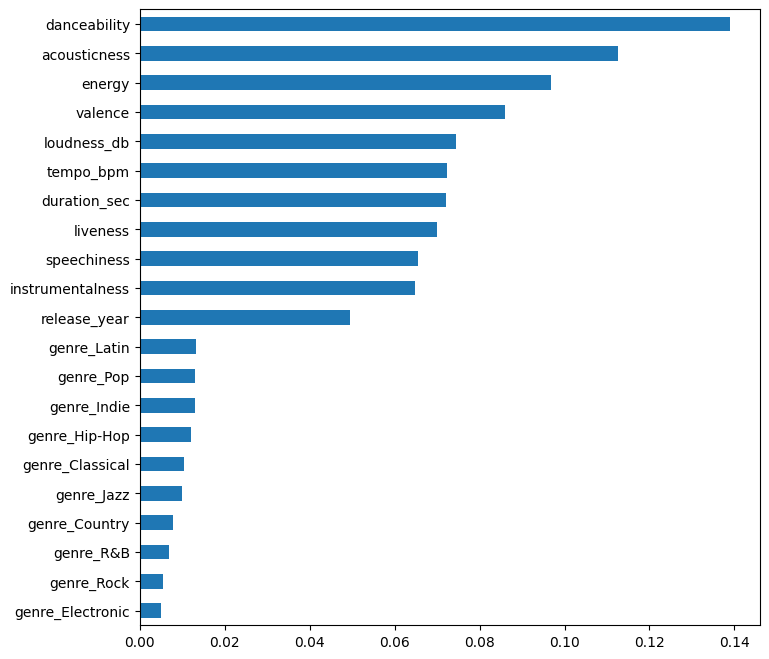

np.float64(0.09674473042111836)

In [23]:
imp = pd.Series(model.feature_importances_, index=x.columns).sort_values()
imp.plot(kind="barh", figsize=(8, 8))
plt.show()

# importance genre digabung
imp[imp.index.str.startswith("genre_")].sum()

In [25]:
from sklearn.model_selection import RandomizedSearchCV

param = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "max_features": ["sqrt", "log2", 0.5],
}

search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param, n_iter=20, cv=5, scoring="f1", random_state=42, n_jobs=-1
)
search.fit(x_train, y_train)

print(search.best_params_)
print(classification_report(y_test, search.best_estimator_.predict(x_test)))

{'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 10}
              precision    recall  f1-score   support

           0       0.78      0.82      0.80      1279
           1       0.64      0.58      0.61       721

    accuracy                           0.73      2000
   macro avg       0.71      0.70      0.70      2000
weighted avg       0.73      0.73      0.73      2000



In [27]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

dummy = DummyClassifier(strategy="most_frequent").fit(x_train, y_train)
print("Baseline akurasi:", dummy.score(x_test, y_test))

# satu pohon keputusan sebagai pembanding langsung
from sklearn.tree import DecisionTreeClassifier
tree = DecisionTreeClassifier(random_state=42).fit(x_train, y_train)
print("Decision Tree:", tree.score(x_test, y_test))
print("Random Forest:", model.score(x_test, y_test))

Baseline akurasi: 0.6395
Decision Tree: 0.6475
Random Forest: 0.7255


In [29]:
lagu = pd.DataFrame([{
    "release_year": 2025, "duration_sec": 200, "danceability": 0.8,
    "energy": 0.7, "valence": 0.6, "tempo_bpm": 120, "acousticness": 0.1,
    "instrumentalness": 0.0, "speechiness": 0.05, "liveness": 0.1,
    "loudness_db": -6, "genre": "Pop"
}])
lagu = pd.get_dummies(lagu, columns=["genre"]).reindex(columns=x.columns, fill_value=0)

print(model.predict(lagu))
print(model.predict_proba(lagu))

[1]
[[0.28 0.72]]


In [30]:
import joblib
joblib.dump(model, "rf_viral.joblib")

# nanti dipakai lagi
model = joblib.load("rf_viral.joblib")